# Feature Scaling: Min-Max Normalization
**Dataset:** UCI Optdigits

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols = [f"pixel_{i}" for i in range(64)] + ["target"]

# Load train and test separately - IMPORTANT: never fit any transformer on test data
train = pd.read_csv("../../data/raw/optdigits.tra", header=None, names=cols)
test  = pd.read_csv("../../data/raw/optdigits.tes", header=None, names=cols)

print("Train shape:", train.shape)   # run this code to obtain actual value
print("Test shape:", test.shape)     # run this code to obtain actual value
train.head()

Train shape: (3823, 65)
Test shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


In [2]:
from sklearn.preprocessing import MinMaxScaler

# --- Fit on TRAIN ONLY, then transform both - avoids data leakage ---
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(train.iloc[:, :64])
X_test_scaled = scaler.transform(test.iloc[:, :64])

print("Before - min/max/mean (pixel_20):",
      train["pixel_20"].min(), train["pixel_20"].max(), train["pixel_20"].mean())  # run this code to obtain actual value
print("After  - min/max/mean (pixel_20):",
      X_train_scaled[:,20].min(), X_train_scaled[:,20].max(), X_train_scaled[:,20].mean())  # run this code to obtain actual value


Before - min/max/mean (pixel_20): 0 16 7.186502746534136
After  - min/max/mean (pixel_20): 0.0 1.0 0.4491564216583835


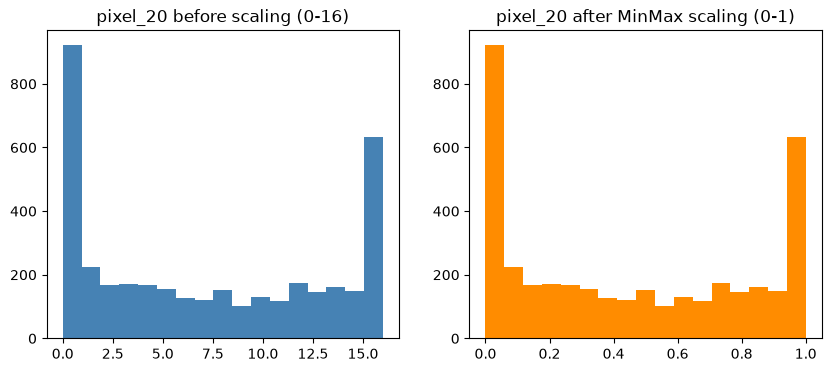

In [ ]:
# --- EDA visualization: before vs after histogram ---
fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].hist(train["pixel_20"], bins=17, color="steelblue")
axes[0].set_title("pixel_20 before scaling (0-16)")
axes[1].hist(X_train_scaled[:,20], bins=17, color="darkorange")
axes[1].set_title("pixel_20 after MinMax scaling (0-1)")
plt.savefig("../../results/eda_visualizations/member3_scaling_hist.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Evaluation

K-Nearest Neighbors classifies a digit from nearby examples, making it a useful test of pixel scaling because distance is sensitive to feature magnitude. This experiment compares raw and MinMax-scaled pixels with tuned neighbor counts and voting weights. Scaling is inside the Pipeline and refit within each fold. Five-fold stratified CV selects the settings; accuracy and macro F1 are then reported on the untouched official test split.

In [2]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

feature_cols = [f"pixel_{index}" for index in range(64)]
X_train = train[feature_cols]
y_train = train["target"].astype(int)
X_test = test[feature_cols]
y_test = test["target"].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
experiments = {
    "KNN - raw pixels": (
        Pipeline([("classifier", KNeighborsClassifier())]),
        {
            "classifier__n_neighbors": [3, 5, 7, 9],
            "classifier__weights": ["uniform", "distance"],
        },
    ),
    "KNN - MinMax scaled": (
        Pipeline([
            ("scaler", MinMaxScaler()),
            ("classifier", KNeighborsClassifier()),
        ]),
        {
            "classifier__n_neighbors": [3, 5, 7, 9],
            "classifier__weights": ["uniform", "distance"],
        },
    ),
}
results = []
for variant_name, (pipeline, parameter_grid) in experiments.items():
    search = GridSearchCV(
        pipeline,
        parameter_grid,
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    predictions = search.predict(X_test)
    results.append({
        "Model variant": variant_name,
        "CV accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
        "CV macro F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro"),
        "Best parameters": search.best_params_,
    })

scaling_model_comparison = pd.DataFrame(results).sort_values(
    "CV macro F1", ascending=False
).reset_index(drop=True)
display(scaling_model_comparison)

,Model variant,CV accuracy,CV macro F1,Test accuracy,Test macro F1,Best parameters
0,KNN - raw pixels,0.985089,0.985166,0.977741,0.977734,"{'classifier__n_neighbors': 7, 'classifier__we..."
1,KNN - MinMax scaled,0.985091,0.985154,0.978854,0.978857,"{'classifier__n_neighbors': 3, 'classifier__we..."


### Results and viva conclusion

The tuned KNN variants achieved nearly identical 5-fold CV macro F1 (98.52%). On the official test split, MinMax-scaled pixels scored 97.89% macro F1 versus 97.77% for raw pixels, a small improvement consistent with distance-based KNN being sensitive to feature scale. MinMax scaling maps each pixel to a common 0-1 range; all learned scaling is fitted within each fold. Limitations include the modest neighbor/weight grid and a single fixed test split. A broader search over distance metrics and neighbor counts could test whether the small gain is robust.